# 01 · Load, Sample & Clean: Lending Club Default Risk

**Goal:** turn the 2.2M-row Lending Club *accepted loans* file into a clean 70K-loan dataset ready for EDA and hypothesis tests.

| Step | What we do | Result |
|---|---|---|
| 1. Load | Read only 23 needed columns, in chunks | Payments / recoveries columns are never loaded, so **no data leakage** |
| 2. Filter | Keep `Fully Paid` and `Charged Off`, issued 2013-2016 | Pool of 1,026,546 loans |
| 3. Sample | 70,000 random loans, `random_state=42` | 70,000 × 24 |
| 4. Clean | Target flag, numeric features, missing values, outliers | 69,981 × 26 |
| 5. Save | Write CSVs to `data/processed/` | `loans_clean.csv` |

**Input:** `data/Raw/accepted_2007_to_2018Q4.csv` ([Kaggle: wordsforthewise/lending-club](https://www.kaggle.com/datasets/wordsforthewise/lending-club)) · **Next notebook:** `02_EDA_and_Hypothesis_Tests`

In [3]:
import pandas as pd
import numpy as np

## 1. Peek at the raw file

`columns` is the shortlist of 23 fields we need (loan terms, borrower profile, credit history, outcome).

> ⚠️ `pd.read_csv(path)` below has no `usecols`, so it loads **all ~150 columns × 2.26M rows** (slow, several GB of RAM). It is only a one-time look at `describe()`. **You can skip this cell on re-runs**; the next cell loads efficiently.

In [4]:
path = '../data/Raw/accepted_2007_to_2018Q4.csv'
columns =  ["loan_amnt","term","int_rate","installment","grade","sub_grade","emp_length",
        "home_ownership","annual_inc","verification_status","issue_d","loan_status",
        "purpose","addr_state","dti","delinq_2yrs","fico_range_low","fico_range_high",
        "open_acc","revol_bal","revol_util","pub_rec","total_acc"]
df= pd.read_csv(path)
print(df.describe())

C:\Users\mauli\AppData\Local\Temp\ipykernel_7396\3520764215.py:6: DtypeWarning: Columns (0: id, 19: desc, 49: next_pymnt_d, 59: verification_status_joint, 118: sec_app_earliest_cr_line, 129: hardship_type, 130: hardship_reason, 131: hardship_status, 134: hardship_start_date, 135: hardship_end_date, 136: payment_plan_start_date, 139: hardship_loan_status, 145: debt_settlement_flag_date, 146: settlement_status, 147: settlement_date) have mixed types. Specify dtype option on import or set low_memory=False.
  df= pd.read_csv(path)


       member_id     loan_amnt   funded_amnt  funded_amnt_inv      int_rate  \
count        0.0  2.260668e+06  2.260668e+06     2.260668e+06  2.260668e+06   
mean         NaN  1.504693e+04  1.504166e+04     1.502344e+04  1.309283e+01   
std          NaN  9.190245e+03  9.188413e+03     9.192332e+03  4.832138e+00   
min          NaN  5.000000e+02  5.000000e+02     0.000000e+00  5.310000e+00   
25%          NaN  8.000000e+03  8.000000e+03     8.000000e+03  9.490000e+00   
50%          NaN  1.290000e+04  1.287500e+04     1.280000e+04  1.262000e+01   
75%          NaN  2.000000e+04  2.000000e+04     2.000000e+04  1.599000e+01   
max          NaN  4.000000e+04  4.000000e+04     4.000000e+04  3.099000e+01   

        installment    annual_inc           dti   delinq_2yrs  fico_range_low  \
count  2.260668e+06  2.260664e+06  2.258957e+06  2.260639e+06    2.260668e+06   
mean   4.458068e+02  7.799243e+04  1.882420e+01  3.068792e-01    6.985882e+02   
std    2.671735e+02  1.126962e+05  1.418333e+

## 2. Load in chunks → filter → sample

Reading 200,000 rows at a time keeps memory small. For each chunk we:

- **Keep only closed loans** (`Fully Paid` / `Charged Off`). `Current` or `Late` loans have no final outcome yet.
- **Parse `issue_d`** into a real date and keep **2013-2016**, so loans have had time to finish.
- Then take a **random sample of 70,000** (`random_state=42` makes it reproducible). `df_raw` is an untouched copy for before/after comparison.

*Caveat:* 60-month loans from late 2016 may still be running and are excluded, which slightly under-represents them.

In [4]:
parts = []

for chunk in pd.read_csv(path , usecols = columns , chunksize = 200_000 , low_memory=False):
    chunk = chunk[chunk['loan_status'].isin(['Fully Paid', 'Charged Off'])].copy()
    chunk['issue_dt'] = pd.to_datetime(chunk['issue_d'] ,format = '%b-%Y',  errors='coerce')
    chunk = chunk[chunk['issue_dt'].dt.year.between(2013,2016)]
    parts.append(chunk)

pool = pd.concat(parts,ignore_index= True)
print(pool.shape)
df_raw = pool.sample(n = 70000, random_state =42 ).reset_index(drop= True)
df = pool.sample(n = 70000, random_state =42 ).reset_index(drop= True)


(1026546, 24)


### Health check on the sample

Look at data types, the columns with most missing values, and the class balance of the outcome: about **79.8% Fully Paid vs 20.2% Charged Off** (moderate imbalance, roughly 4:1).

In [5]:
df.info()
df.isna().mean().sort_values(ascending = False).head(10)
df.describe()
df['loan_status'].value_counts(normalize = True)

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   loan_amnt            70000 non-null  float64       
 1   term                 70000 non-null  str           
 2   int_rate             70000 non-null  float64       
 3   installment          70000 non-null  float64       
 4   grade                70000 non-null  str           
 5   sub_grade            70000 non-null  str           
 6   emp_length           65983 non-null  str           
 7   home_ownership       70000 non-null  str           
 8   annual_inc           70000 non-null  float64       
 9   verification_status  70000 non-null  str           
 10  issue_d              70000 non-null  str           
 11  loan_status          70000 non-null  str           
 12  purpose              70000 non-null  str           
 13  addr_state           70000 non-null  str  

loan_status
Fully Paid     0.797757
Charged Off    0.202243
Name: proportion, dtype: float64

## 3. Cleaning

Rule of thumb: **fix, cap or flag; only delete rows that are impossible.** Each step below says what we change and why.

### 3.1 Target variable

`default = 1` if the loan was **Charged Off**, else `0`. This single flag is what every later analysis explains.

In [6]:

#Target feature
df['default'] = (df['loan_status'] == 'Charged Off').astype(int)


### 3.2 `term`: text → number

Values look like `" 36 months"`. A regex pulls out the digits so term becomes numeric (36 or 60) and can be grouped and tested.

In [ ]:
#term -> 36 months converting to number
df['term'] = df["term"].str.extract(r'(\d+)')[0].astype(int)

### 3.3 `int_rate`: make sure it is numeric

In some Lending Club files the rate is text like `"13.5%"`. This strips the `%` and converts to float (harmless if already numeric).

In [8]:
#int_rate : handle text with percentage if present
df['int_rate'] = df['int_rate'].astype(str).str.replace("%" , "").astype(float)

### 3.4 `emp_length` → `emp_years` (+ missing flag)

- `"10+ years"` → 10, `"< 1 year"` → 0.
- Missing values are **flagged** in `emp_missing` (missing can itself be a signal), then filled with the **median**.

In [9]:
# emp_length : text -> years ; keeping a missing flag
s = df['emp_length']
df['emp_missing'] = s.isna().astype(int)
df['emp_years'] = s.str.extract(r'(\d+)')[0].astype(float)
df.loc[s == "< 1 year" , 'emp_years'] = 0
df['emp_years'] = df['emp_years'].fillna(df['emp_years'].median())

### 3.5 Dates

`issue_d` (e.g. `Jan-2016`) becomes a datetime `issue_dt`, plus `issue_year` for grouping.

In [10]:
#dates
df['issue_dt'] = pd.to_datetime(df['issue_d'] ,format= '%b-%Y')
df['issue_year'] = df['issue_dt'].dt.year

### 3.6 FICO average

Lending Club gives a FICO *range* (low-high). The midpoint `fico_avg` is a single, easy-to-use credit score.

In [11]:
#fico avg
df['fico_avg'] = (df["fico_range_low"]+df["fico_range_high"])/2

### 3.7 `revol_util` (revolving utilisation)

Very few values are missing → fill with the **median**. Cap at **100%** to fix the odd value above full utilisation.

In [12]:
#missing revol_util(very few) fill with meadian
df["revol_util"] = df["revol_util"].fillna(df["revol_util"].median())
df["revol_util"] = df["revol_util"].clip(upper=100)


### 3.8 `verification_status` check

Three clean levels (`Verified`, `Source Verified`, `Not Verified`), so no cleaning is needed.

In [13]:
#verification
df['verification_status'].unique()

<StringArray>
['Verified', 'Source Verified', 'Not Verified']
Length: 3, dtype: str

### 3.9 Duplicates

Drop exact duplicate rows so no loan is counted twice.

In [14]:
#duplicates
df = df.drop_duplicates()

### 3.10 Income outliers: cap, don't delete

`annual_inc` is heavily right-skewed (a few very high earners). Instead of deleting them we add:

- `annual_inc_capped`: income capped at the **99th percentile**.
- `log_income`: log-transform (`log1p`) to reduce skew (next cell shows the improvement).

The original `annual_inc` is **kept**; the t-test in notebook 02 uses it.

<Axes: xlabel='annual_inc', ylabel='Count'>

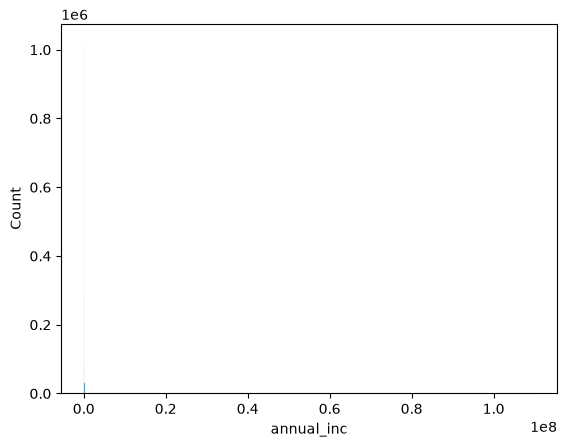

In [ ]:
# 10. income outliers: cap, don't delete
import seaborn as sns
sns.histplot(data = df , x = 'annual_inc')

cap = df["annual_inc"].quantile(0.99)
df["annual_inc_capped"] = df["annual_inc"].clip(upper=cap)
df["log_income"] = np.log1p(df["annual_inc"])



The log transform makes income roughly bell-shaped, which is better for plots and any future modelling.

<Axes: xlabel='log_income', ylabel='Count'>

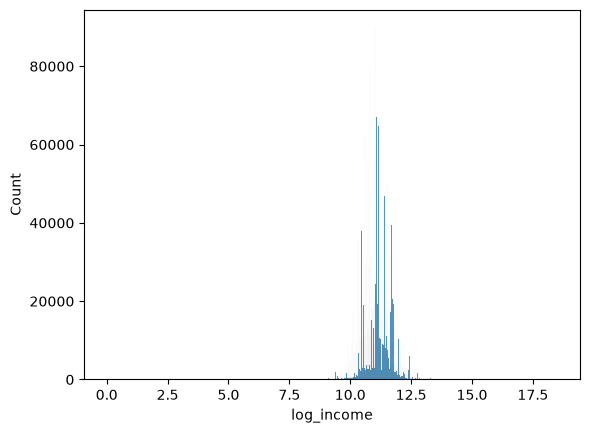

In [11]:
sns.histplot(data = df , x = 'log_income')

### 3.11 Remove impossible DTI + drop used-up columns

- **DTI** (debt-to-income, %) must be between **0 and 60**. Rows outside that range (or missing) are removed, which is why 70,000 → **69,981** rows overall.
- Dropped columns are now redundant: `loan_status` (replaced by `default`), `issue_d` (replaced by `issue_dt`), `fico_range_low/high` (replaced by `fico_avg`), `emp_length` (replaced by `emp_years`).

In [16]:
#dti: remove impossible values
df = df[(df['dti']>= 0) & (df['dti'] <=60)]
df = df.drop(columns = ['loan_status' , 'issue_d' , 'fico_range_low' , 'fico_range_high' , 'emp_length' ])

## 4. Final check

Confirm **69,981 rows × 26 columns**, no missing values and correct data types.

In [17]:
df.info()
df.head()

<class 'pandas.DataFrame'>
Index: 69981 entries, 0 to 69999
Data columns (total 26 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   loan_amnt            69981 non-null  float64       
 1   term                 69981 non-null  int64         
 2   int_rate             69981 non-null  float64       
 3   installment          69981 non-null  float64       
 4   grade                69981 non-null  str           
 5   sub_grade            69981 non-null  str           
 6   home_ownership       69981 non-null  str           
 7   annual_inc           69981 non-null  float64       
 8   verification_status  69981 non-null  str           
 9   purpose              69981 non-null  str           
 10  addr_state           69981 non-null  str           
 11  dti                  69981 non-null  float64       
 12  delinq_2yrs          69981 non-null  float64       
 13  open_acc             69981 non-null  float64   

,loan_amnt,term,int_rate,installment,grade,sub_grade,home_ownership,annual_inc,verification_status,purpose,...,revol_util,total_acc,issue_dt,default,emp_missing,emp_years,issue_year,fico_avg,annual_inc_capped,log_income
0,3825.0,36,17.57,137.46,D,D4,RENT,70000.0,Verified,debt_consolidation,...,26.1,13.0,2016-01-01,1,0,2.0,2016,677.0,70000.0,11.156265
1,13000.0,36,12.29,433.59,C,C1,RENT,70000.0,Verified,debt_consolidation,...,76.0,17.0,2015-07-01,0,0,2.0,2015,672.0,70000.0,11.156265
2,7000.0,36,9.17,223.16,B,B2,MORTGAGE,40000.0,Verified,debt_consolidation,...,29.8,17.0,2015-10-01,0,0,0.0,2015,677.0,40000.0,10.596660
3,25000.0,36,6.39,764.98,A,A2,RENT,125000.0,Source Verified,credit_card,...,69.2,17.0,2015-05-01,0,0,10.0,2015,752.0,125000.0,11.736077
4,6500.0,36,15.61,227.28,D,D1,MORTGAGE,26500.0,Source Verified,debt_consolidation,...,99.1,20.0,2015-04-01,0,0,8.0,2015,677.0,26500.0,10.184938


## 5. Save

Two files are written to `data/processed/`:
- `loans_clean.csv`: the analysis-ready dataset used by notebook 02 and the dashboard.
- `sample_70k_raw.csv`: the untouched sample (git-ignored; re-created by running this notebook).

In [18]:
df.to_csv("../data/processed/loans_clean.csv", index=False)
df_raw.to_csv("../data/processed/sample_70k_raw.csv", index=False)

---
**Next:** open `02_EDA_and_Hypothesis_Tests.ipynb` (reads `../data/processed/loans_clean.csv`).